<a href="https://colab.research.google.com/github/nothyfaria5-netizen/Fonte_de_Informacao_e_Banco_de_Dados/blob/main/Sorvete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sakshisatre/ice-cream-sales-dataset")

print("Path to dataset files:", path)

100%|██████████| 2.09k/2.09k [00:00<00:00, 2.57MB/s]

Extracting files...
Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/sakshisatre/ice-cream-sales-dataset/versions/1
Path to dataset files: /root/.cache/kagglehub/datasets/sakshisatre/ice-cream-sales-dataset/versions/1


In [ ]:
import os
import pandas as pd

# Listar os arquivos do diretório baixado
arquivos = os.listdir(path)
print("Arquivos no diretório:", arquivos)

# Encontrar o arquivo CSV
csv_nome = [f for f in arquivos if f.endswith('.csv')][0]
csv_caminho = os.path.join(path, csv_nome)

# Carregar no DataFrame
df = pd.read_csv(csv_caminho)

# Mostrar as primeiras linhas do DataFrame
df.head()

Arquivos no diretório: ['Ice Cream.csv']


,Temperature,Revenue
0,24.6,535
1,26.1,626
2,27.8,661
3,20.6,488
4,11.6,317


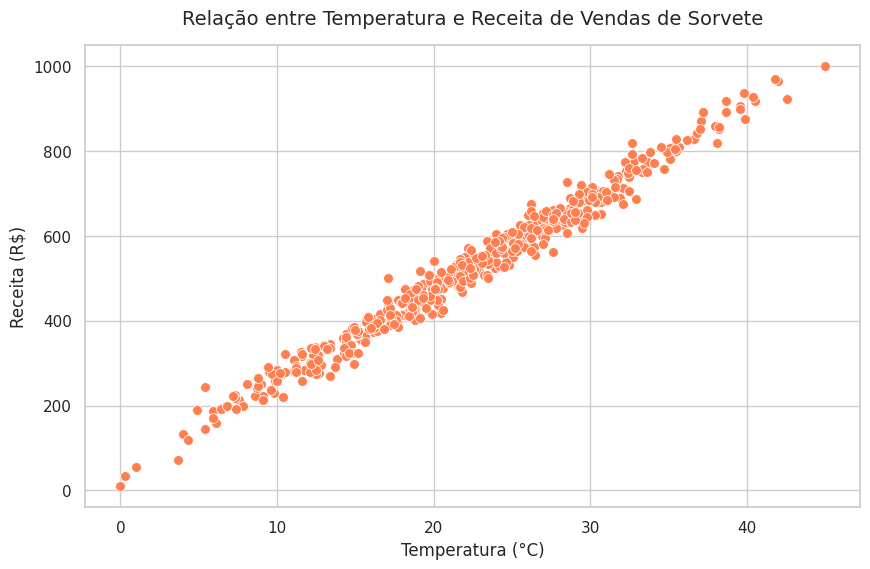

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo do gráfico
sns.set_theme(style="whitegrid")

# Criar a figura
plt.figure(figsize=(10, 6))

# Gerar o gráfico de dispersão
sns.scatterplot(data=df, x='Temperature', y='Revenue', color='coral', edgecolor='w', s=50)

# Adicionar títulos e rótulos aos eixos
plt.title('Relação entre Temperatura e Receita de Vendas de Sorvete', fontsize=14, pad=15)
plt.xlabel('Temperatura (°C)', fontsize=12)
plt.ylabel('Receita (R$)', fontsize=12)

# Exibir o gráfico
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
import numpy as np

# Definir variáveis preditora (X) e alvo (y)
X = df[['Temperature']]
y = df['Revenue']

# Dividir os dados em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Inicializar e treinar o modelo de Regressão Linear
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Fazer previsões no conjunto de teste
y_pred = modelo.predict(X_test)

# Calcular métricas de avaliação
r2 = metrics.r2_score(y_test, y_pred)
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

# Exibir os resultados do modelo
print("=== Resultados do Modelo de Regressão Linear ===")
print(f"Coeficiente (Inclinação): {modelo.coef_[0]:.4f}")
print(f"Intercepto (Ajuste Inicial): {modelo.intercept_:.4f}")
print(f"R² Score (Coeficiente de Determinação): {r2:.4f}")
print(f"Erro Médio Absoluto (MAE): {mae:.4f}")
print(f"Raiz do Erro Quadrático Médio (RMSE): {rmse:.4f}")
print("================================================")

# Exemplo prático de previsão
temp_exemplo = [[30]]
predicao_exemplo = modelo.predict(temp_exemplo)
print(f"Previsão de Receita para uma temperatura de 30°C: R$ {predicao_exemplo[0]:.2f}")

=== Resultados do Modelo de Regressão Linear ===
Coeficiente (Inclinação): 21.3840
Intercepto (Ajuste Inicial): 46.1783
R² Score (Coeficiente de Determinação): 0.9772
Erro Médio Absoluto (MAE): 19.1957
Raiz do Erro Quadrático Médio (RMSE): 25.5440
Previsão de Receita para uma temperatura de 30°C: R$ 687.70


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
